# 2. Did the coupon booklets work?

Recipients spent far more than non-recipients during the campaigns. The question is how much of that the
booklet *caused*. Because recipients were picked from their purchase history, the naive gap mostly measures
the targeting rule.

**Design:** for each of the 4 Type A waves:
1. a baseline window of up to 8 weeks before the wave (never overlapping the previous wave),
2. match each recipient to a non-recipient who looked the same in the baseline,
3. compare the *change* in weekly spend (difference-in-differences on matched pairs),
4. check it: covariate balance, event study, placebo, robustness specs, a matching-free estimator.

In [1]:
import json
import warnings

import pandas as pd
from IPython.display import Image, Markdown, display

from couponroi import config
from couponroi.warehouse import connect

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
con = connect()  # read-only DuckDB warehouse built by `couponroi build`
R = lambda name: json.loads((config.RESULTS_DIR / f"{name}.json").read_text())  # noqa: E731
fig = lambda name, width=900: display(Image(filename=str(config.FIG_DIR / f"{name}.png"), width=width))  # noqa: E731
sql = lambda path: (config.SQL_DIR / path).read_text()  # noqa: E731
from couponroi.causal import analyze_wave, list_waves, unit_table

In [2]:
waves = list_waves(con)
pd.DataFrame([{**w.__dict__, "pre_weeks": w.pre_weeks, "post_weeks": w.post_weeks} for w in waves])

,wave,campaign_id,pre_start,start,end,pre_weeks,post_weeks
0,1,27,2,7,13,5,7
1,2,8,14,20,26,6,7
2,3,13,27,33,39,6,7
3,4,18,40,45,52,5,8


## One wave up close: wave 2 (campaign 8)

One row per household that shopped in the baseline. `dy` is campaign-period weekly spend minus baseline weekly spend.

In [3]:
u = unit_table(con, waves[1])
g = u.groupby("treated")[["pre_spend", "pre_trips", "pre_active_share", "prior_waves", "co_exposure_post", "post_spend", "dy"]].mean()
display(g)
print(f"recipients spent {g.loc[1, 'pre_spend'] / g.loc[0, 'pre_spend']:.1f}x more per week BEFORE the booklet; "
      f"change in weekly spend: recipients {g.loc[1, 'dy']:+.2f}, non-recipients {g.loc[0, 'dy']:+.2f}")

,pre_spend,pre_trips,pre_active_share,prior_waves,co_exposure_post,post_spend,dy
treated,,,,,,,
0,23.696,0.910,0.492,0.095,0.069,23.104,-0.592
1,52.979,1.898,0.763,0.234,0.356,52.064,-0.915


recipients spent 2.2x more per week BEFORE the booklet; change in weekly spend: recipients -0.91, non-recipients -0.59


The levels are far apart before anything was mailed, but the *changes* are close. That's the whole story in one
table; the matching below makes it rigorous by comparing each recipient with a non-recipient who looked the same.

**Matching:** propensity score (logistic regression on 12 baseline covariates), exact match on two discrete
variables (got another campaign during the wave; number of earlier booklets), then the nearest look-alike on
spend and activity (Mahalanobis distance) inside a tight propensity caliper.

In [4]:
res, matched = analyze_wave(con, waves[1])
pd.DataFrame(res["balance"]).set_index("covariate").round(3)

,before,after
covariate,,
pre_spend,0.780,0.031
pre_trips,0.699,0.048
pre_active_share,1.038,0.014
pre_departments,0.992,0.048
pre_private_share,0.031,-0.005
pre_promo_share,0.039,-0.028
pre_coupon_use,0.410,0.060
pre_trend,0.003,-0.010
prior_spend,0.963,0.002


In [5]:
pd.DataFrame({k: res[k] for k in ["naive_post", "did_unmatched", "did_matched", "did_matched_dr"]}).T[["est", "lo", "hi", "p"]]

,est,lo,hi,p
naive_post,28.959,25.720,32.199,0.000
did_unmatched,-0.323,-2.459,1.814,0.767
did_matched,-0.606,-3.826,2.613,0.712
did_matched_dr,-0.245,-3.197,2.706,0.871


## All four waves

In [6]:
c = R("causal")
rows = [{"wave": w["wave"], "recipients": w["n_treated"], "matched": w["n_pairs"],
         "naive": w["naive_post"]["est"], "matched DiD": w["did_matched"]["est"],
         "CI low": w["did_matched"]["lo"], "CI high": w["did_matched"]["hi"],
         "max |SMD| after": w["max_abs_smd_after"]} for w in c["waves"]]
p = c["pooled"]
rows.append({"wave": "pooled", "recipients": p["n_treated"], "matched": p["n_pairs"], "naive": p["naive_post"]["est"],
             "matched DiD": p["did_matched"]["est"], "CI low": p["did_matched"]["lo"], "CI high": p["did_matched"]["hi"]})
display(pd.DataFrame(rows))
display(Markdown(c["headline"]))

,wave,recipients,matched,naive,matched DiD,CI low,CI high,max |SMD| after
0,1,344,319,15.478,3.685,-0.782,8.151,0.099
1,2,1056,449,28.959,-0.606,-3.826,2.613,0.062
2,3,1058,306,32.829,3.532,-0.099,7.163,0.074
3,4,1103,335,32.383,-1.832,-5.252,1.589,0.109
4,pooled,3561,1409,28.968,0.972,-0.849,2.794,NaN


Recipients spent $29/week more than non-recipients during the waves, but after matching on pre-wave behaviour the booklets' effect was +0.97 $/week (+2.4%, 95% CI -2.1% to +7.0%) across 1,409 matched pairs in 4 waves.

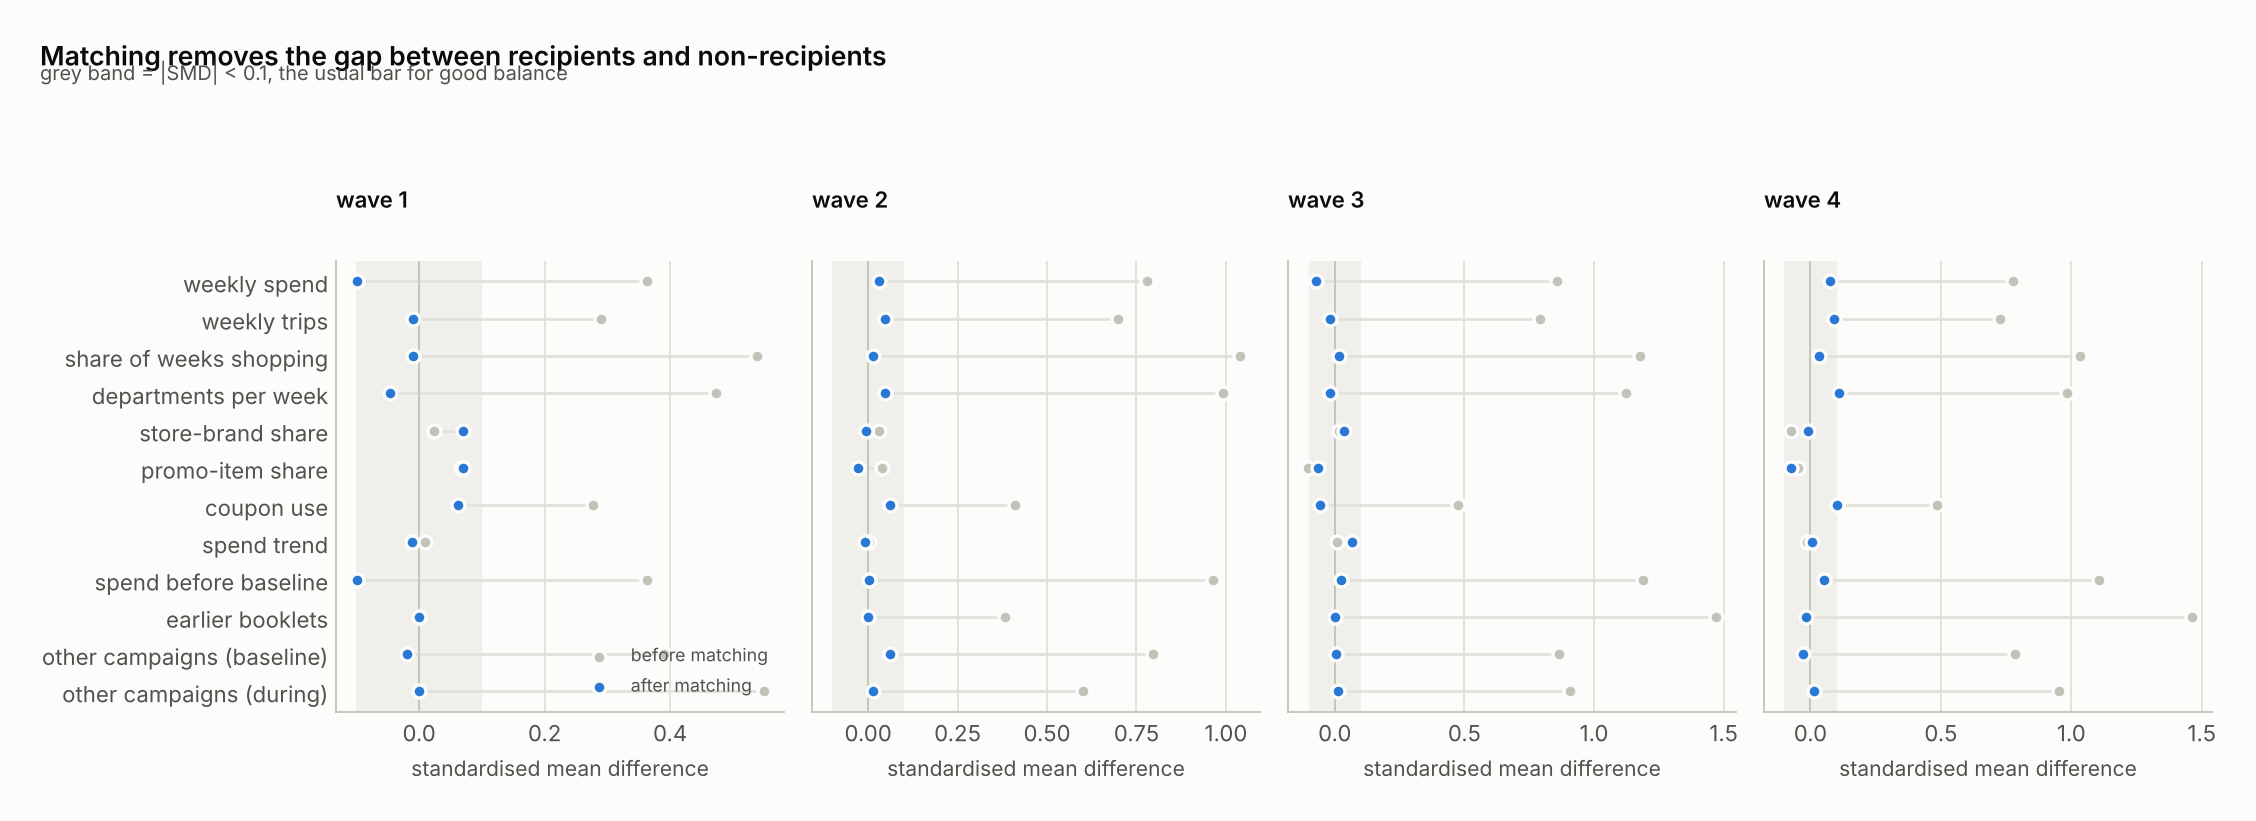

In [7]:
fig('causal_1_balance', 1000)

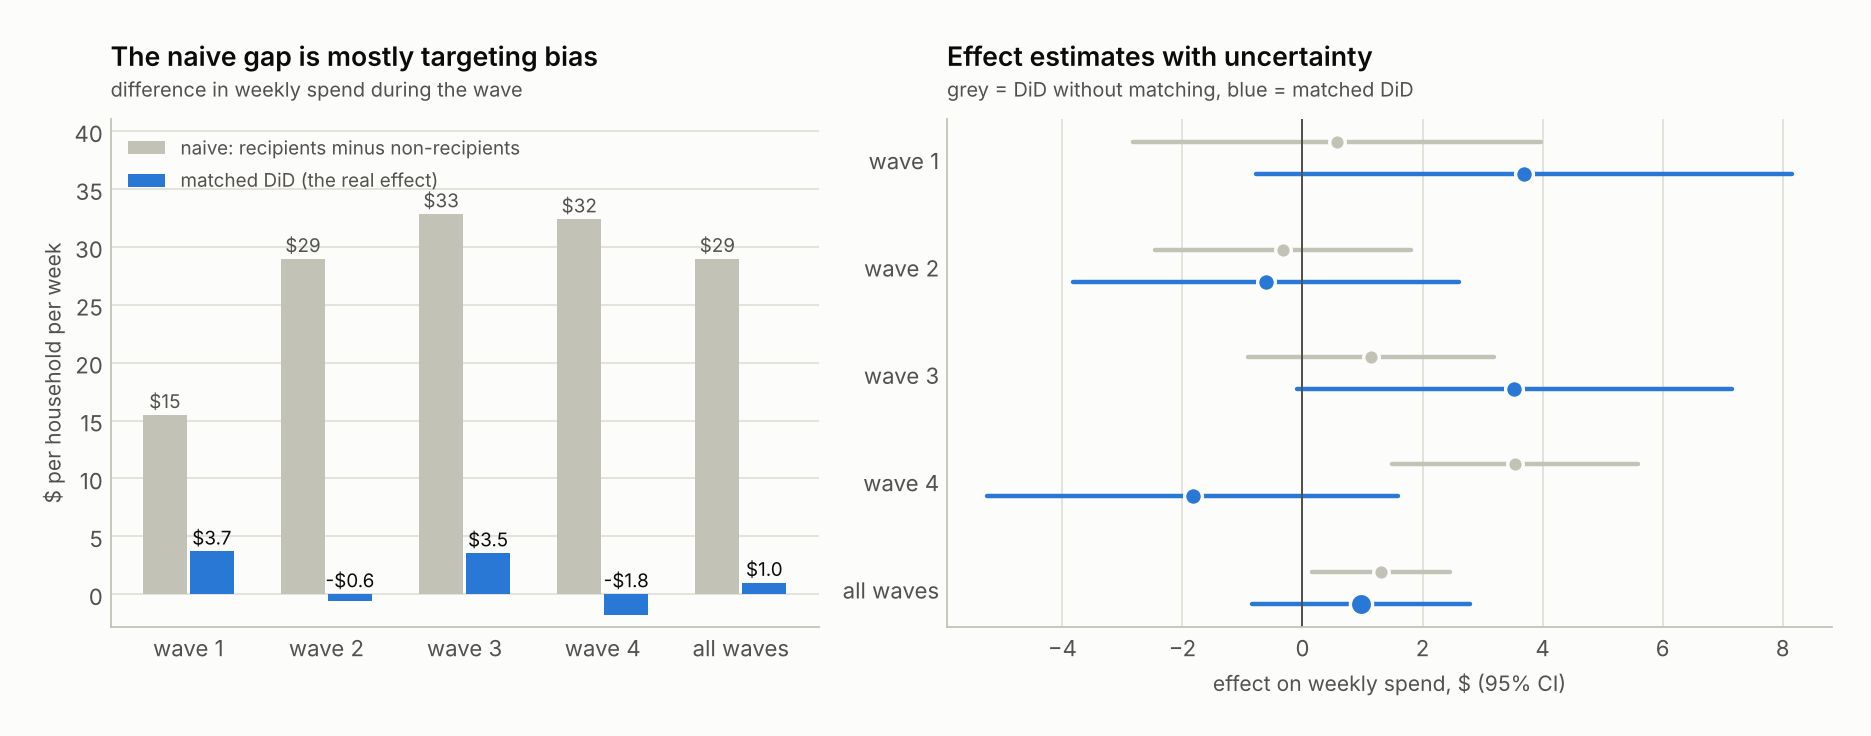

In [8]:
fig('causal_2_estimates', 1000)

## Is the comparison fair? Event study

If matched recipients and their look-alikes were already drifting apart before the booklet, the DiD would be
biased. The weeks before 0 should hover around zero.

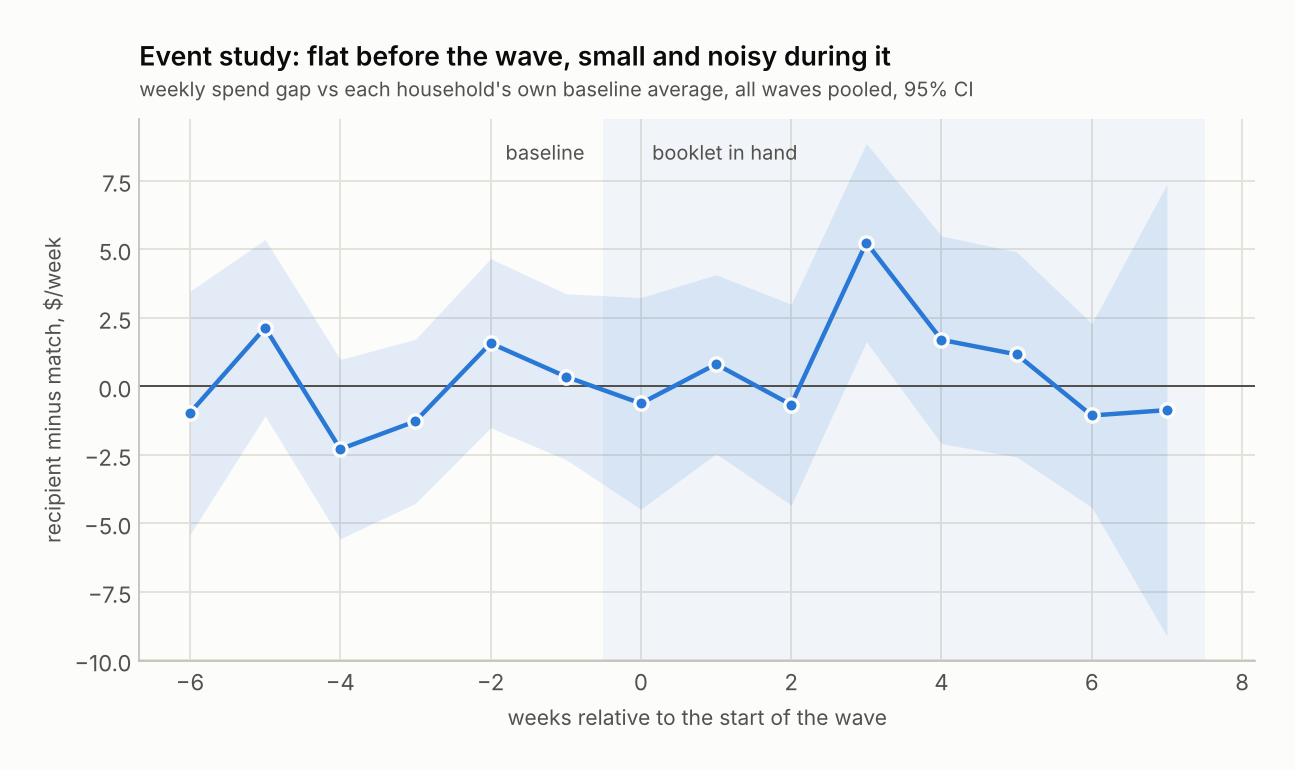

In [9]:
fig('causal_3_event_study', 820)

In [10]:
pd.DataFrame(R('causal')['event_study'])[['rel_week', 'waves', 'est', 'lo', 'hi', 'p']]

,rel_week,waves,est,lo,hi,p
0,-6,2,-0.965,-5.402,3.472,0.670
1,-5,4,2.141,-1.075,5.357,0.192
2,-4,4,-2.288,-5.561,0.984,0.170
3,-3,4,-1.271,-4.262,1.719,0.405
4,-2,4,1.576,-1.509,4.662,0.317
5,-1,4,0.359,-2.664,3.382,0.816
6,0,4,-0.620,-4.481,3.241,0.753
7,1,4,0.812,-2.454,4.077,0.626
8,2,4,-0.667,-4.331,2.997,0.721
9,3,4,5.247,1.629,8.865,0.004


## Robustness and placebo

In [11]:
pd.DataFrame(R('causal')['robustness'])[['spec', 'est', 'lo', 'hi', 'p', 'n_pairs']]

,spec,est,lo,hi,p,n_pairs
0,main: matched DiD,0.972,-0.849,2.794,0.295,"1,409.000"
1,+ regression adjustment (doubly robust),0.979,-0.749,2.707,0.267,"1,409.000"
2,looser caliper (0.2 SD),0.961,-0.742,2.664,0.269,"1,581.000"
3,matching with replacement,0.973,-1.353,3.298,0.412,"3,088.000"
4,no other campaigns during the wave,1.732,-0.180,3.643,0.076,"1,145.000"
5,propensity only (no exact matching),1.320,-0.462,3.102,0.147,"1,490.000"
6,spend + trips only (fewer covariates),1.920,0.107,3.732,0.038,"1,393.000"
7,"DR-DiD weighting, no matching (Sant'Anna-Zhao)",0.526,-3.796,4.849,0.811,NaN
8,placebo: fake start mid-baseline,0.276,-2.562,3.113,0.849,NaN
9,unmatched DiD (no matching),1.307,0.156,2.458,0.026,NaN


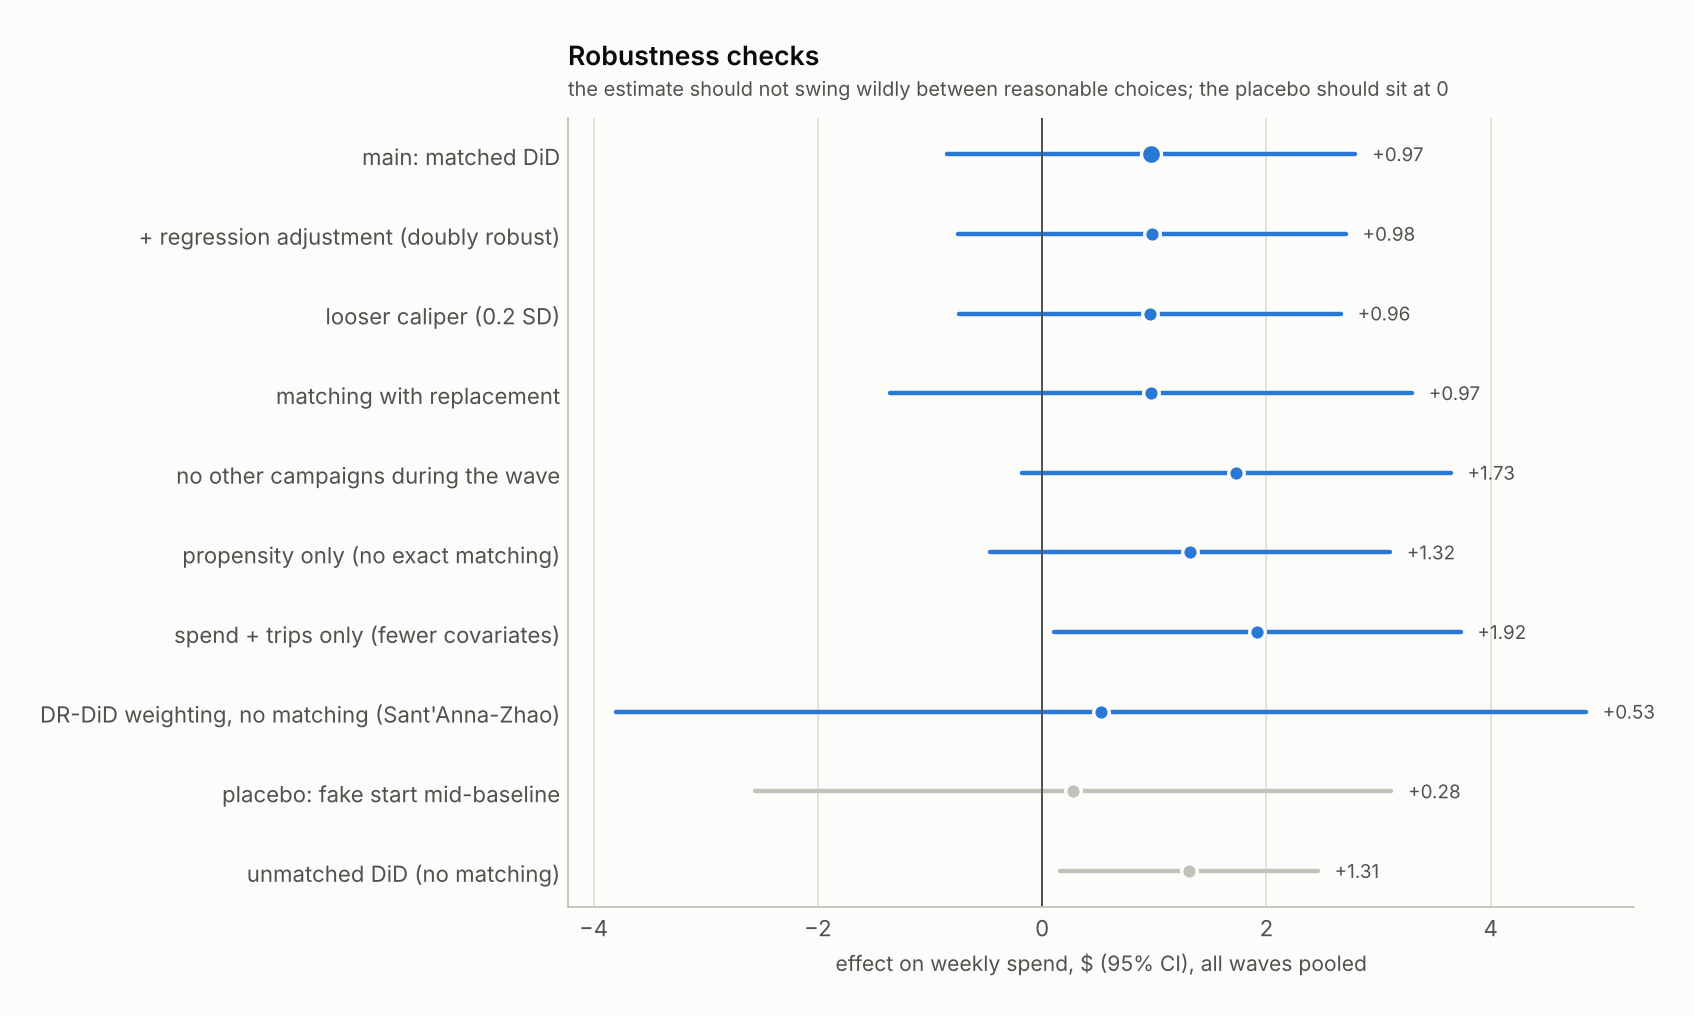

In [12]:
fig('causal_4_robustness', 820)

## Who responds? And a trap worth showing

My first version cut segments (light / medium / heavy shoppers) on spend in the *same* baseline window used for
the DiD. It found big effects for light shoppers and negative effects for heavy ones:

In [13]:
pd.DataFrame(R('causal')['segments_regression_to_mean_trap'])[['segment', 'n_pairs', 'est', 'lo', 'hi']]

,segment,n_pairs,est,lo,hi
0,light,471,4.273,1.984,6.562
1,medium,468,2.767,-0.094,5.628
2,heavy,470,-4.122,-8.074,-0.171


That's regression to the mean. A household with an unusually quiet baseline lands in "light" and then bounces
back, which looks like a booklet effect. Defining segments on behaviour from *before* the baseline fixes it,
and the differences disappear:

In [14]:
pd.DataFrame(R('causal')['segments'])[['dimension', 'segment', 'n_pairs', 'est', 'lo', 'hi']]

,dimension,segment,n_pairs,est,lo,hi
0,spend_tier,light,364,-1.814,-4.335,0.708
1,spend_tier,medium,362,0.570,-2.530,3.670
2,spend_tier,heavy,364,1.782,-2.464,6.028
3,booklet_seg,first booklet,607,-0.206,-2.831,2.418
4,booklet_seg,had a booklet before,483,0.663,-2.256,3.581
5,coupon_seg,never used coupons,504,-0.654,-3.262,1.953
6,coupon_seg,used coupons before,586,0.895,-1.999,3.789


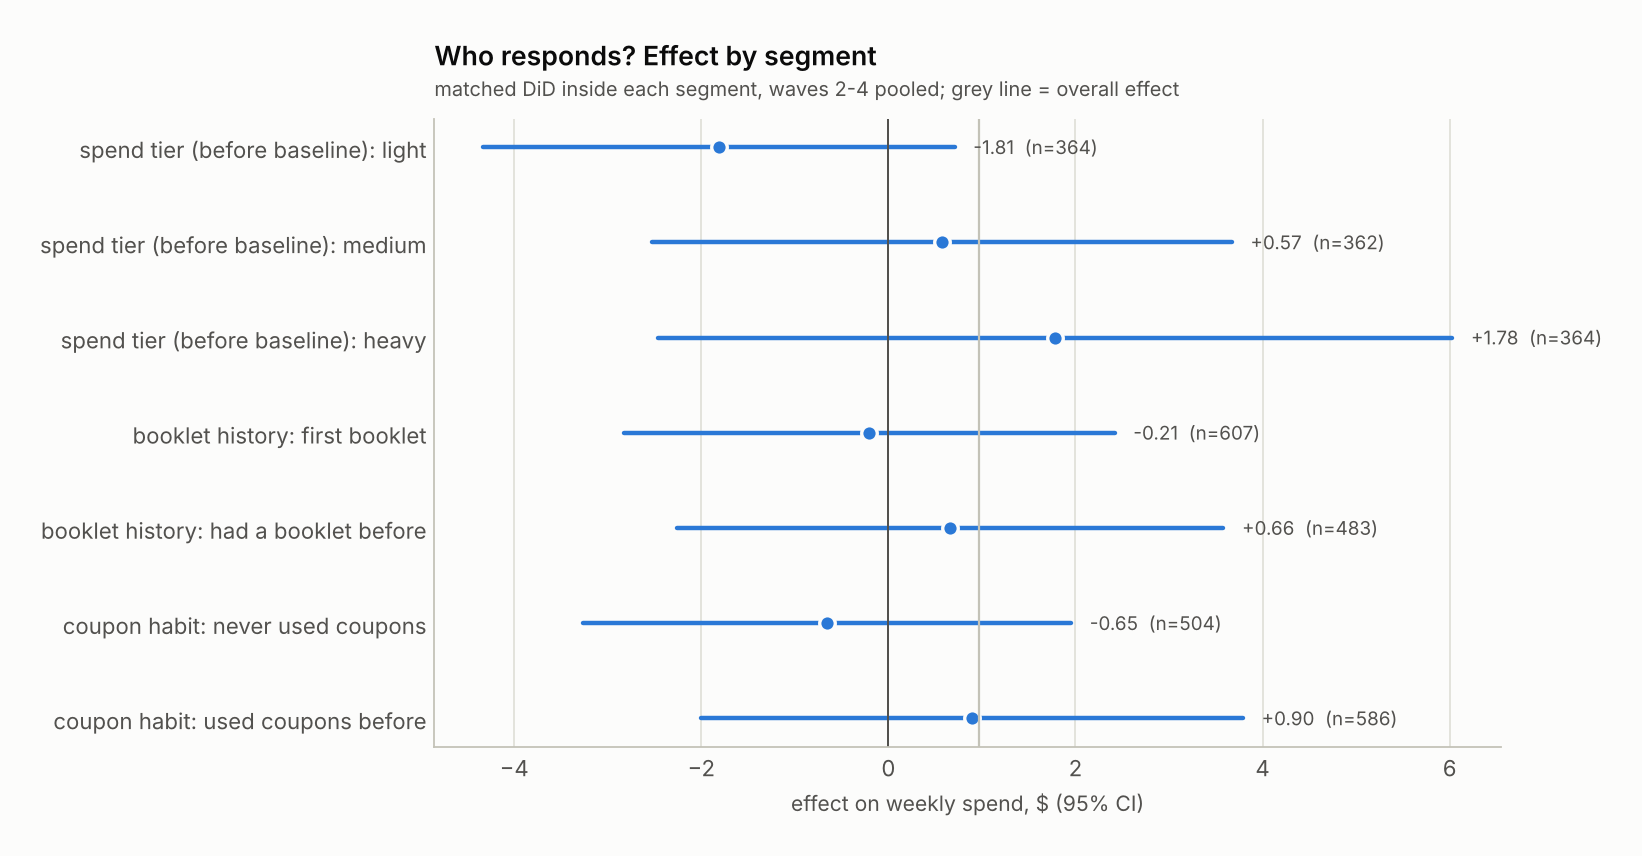

In [15]:
fig('causal_6_segments', 820)

## Planning the next test: CUPED and power

In [16]:
cu, pw = R("causal")["cuped"], R("causal")["power"]
display(pd.DataFrame({k: cu[k] for k in ["post_only", "did", "cuped"]}).T[["est", "se", "lo", "hi"]])
print(f"CUPED theta = {cu['theta']:.2f}, variance reduction vs post-only = {cu['variance_reduction_vs_post']:.0%}")
print(f"households per arm to detect {pw['effect_used']:.2f} $/wk at 80% power: "
      f"{pw['n_per_arm_plain']:,.0f} plain, {pw['n_per_arm_cuped']:,.0f} with CUPED (a typical wave has ~1,100)")

,est,se,lo,hi
post_only,0.495,1.617,-2.674,3.665
did,0.972,0.929,-0.849,2.794
cuped,0.880,0.914,-0.912,2.671


CUPED theta = 0.81, variance reduction vs post-only = 68%
households per arm to detect 0.97 $/wk at 80% power: 22,562 plain, 8,308 with CUPED (a typical wave has ~1,100)


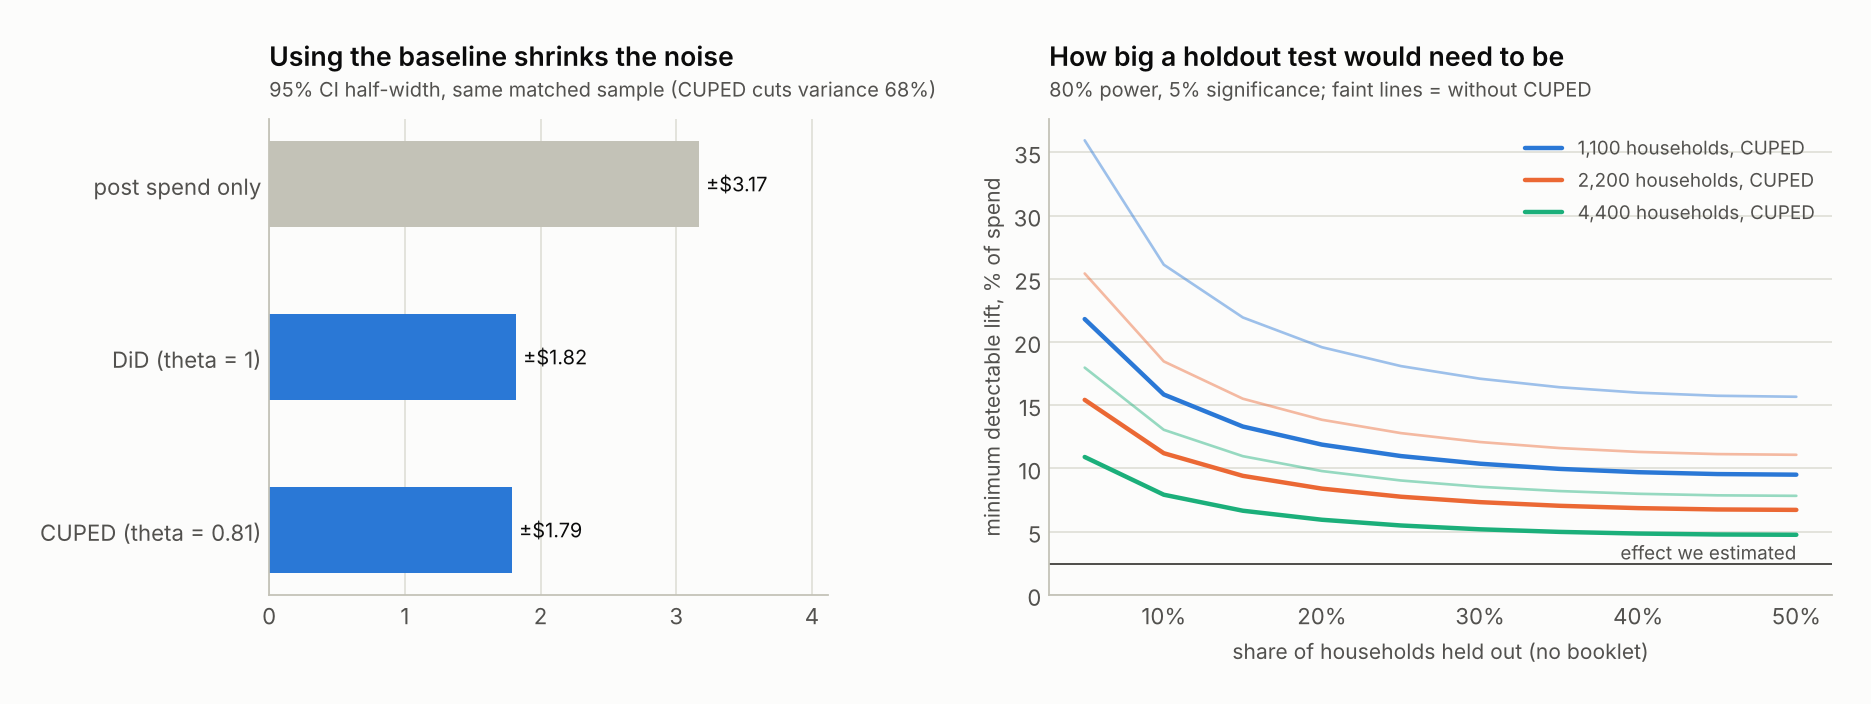

In [17]:
fig('causal_5_cuped_power', 1000)

## Did a booklet pay for itself? (simulated)

In [18]:
roi = R("causal")["roi"]
print(json.dumps(roi["assumptions"]))
print(f"break-even: {roi['breakeven_lift_per_week']:.2f} $/wk ({roi['breakeven_rel']:.1%} of baseline spend)")
print(f"profit per booklet: {roi['simulated_profit_per_booklet']:+.2f} (95% CI {roi['simulated_profit_lo']:+.2f} to {roi['simulated_profit_hi']:+.2f})")

{"gross_margin": 0.28, "cost_per_booklet": 1.5, "weeks": 7.25}
break-even: 0.74 $/wk (1.9% of baseline spend)
profit per booklet: +0.47 (95% CI -3.22 to +4.17)


## Conclusion

The booklets added about **$1 per household per week** (+2.4%), which is roughly break-even at a 28% margin and
$1.50 a booklet. The naive comparison would have said $29. A single wave is far too small to measure an effect
this size, so the next campaign should include a randomised holdout, pooled across waves, with CUPED.